# kNN 알고리즘

In [1]:
# 라이브러리 임포트 : 실습에 필요한 라이브러리를 임포트 

# 데이터 분석
import numpy as np                        

# 데이터 분석 
import pandas as pd                       

# 시각화
import matplotlib.pyplot as plt           

# 시각화
import seaborn as sns                     

# scikit-learn 에서 머신러닝 모델을 화면에 어떻게 표현할지 설정 
from sklearn import set_config

# Jupyter Notebook에서 머신러닝 모델을 출력할 때 그림 대신 텍스트로 보여달라는 설정
set_config(display='text')

# 경고 안보이게 처리 
import warnings
warnings.filterwarnings("ignore")

# sklearn 모델의 동일한 결과 출력을 위해 랜덤시드 설정 
np.random.seed(1234)

# 데이터 불러오기 ( 학습데이터, 테스트 데이터 )

##### - 데이터 분석 단계에서 생성한 농구 선수 포지션 예측하기의 학습 데이터 및 테스트 데이터를 읽어오기

In [2]:
df_train = pd.read_csv("./data/csv/basketball_train.csv")
df_test = pd.read_csv("./data/csv/basketball_test.csv")

# 훈련용 행의 데이터 개수 
print(df_train.shape[0])    

# 훈련용 열의 데이터 개수 
print(df_train.shape[1])


# 테스트 행의 데이터 개수 
print(df_test.shape[0])    

# 테스트 행의 데이터 개수 
print(df_test.shape[1])

80
5
20
5


# 최적의 k 찾기 ( 교차 검증 - cross calidation )

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

In [ ]:
# 최적의 k 값 찾기

# //연산자 몫 만 반환
# k 값 체크는 전체 데이터 개수의 절반만 체크 해도 된다
max_k_range = df_train.shape[0] // 2
k_list = []

# 1,2 는 보통 안쓰임 짝수값은 건더띔 
for i in range(3, max_k_range, 2):
  k_list.append(i)

x_train = df_train[['3P', 'BLK','TRB']]
y_train = df_train[['Pos']]

print(x_train.shape)
print(y_train.shape)

print(x_train)
print(y_train)


(80, 3)
(80, 1)
     3P  BLK  TRB
0   1.8  0.4  6.2
1   1.8  0.1  3.3
2   0.0  1.4  6.4
3   0.0  0.6  4.2
4   0.0  0.6  4.5
..  ...  ...  ...
75  1.4  0.3  2.6
76  1.3  0.4  2.8
77  0.8  0.7  4.5
78  0.0  0.8  9.5
79  2.1  0.1  1.5

[80 rows x 3 columns]
   Pos
0   SG
1   SG
2    C
3    C
4    C
..  ..
75  SG
76  SG
77  SG
78   C
79  SG

[80 rows x 1 columns]
[['SG']
 ['SG']
 ['C']
 ['C']
 ['C']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['SG']
 ['C']
 ['C']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['SG']
 ['SG']
 ['C']
 ['C']
 ['SG']
 ['C']
 ['SG']
 ['SG']
 ['SG']
 ['C']
 ['C']
 ['SG']
 ['C']
 ['SG']
 ['C']
 ['SG']
 ['SG']
 ['C']
 ['SG']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['C']
 ['SG']
 ['SG']
 ['C']
 ['SG']
 ['C']
 ['SG']
 ['C']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['C']
 ['SG']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['SG']
 ['SG']
 ['C']
 ['C']
 ['C']
 ['C']
 ['C']
 ['C']
 ['SG']
 ['C']
 ['C']
 ['C']
 ['C']
 ['SG']
 ['SG']
 ['SG']
 ['SG']
 ['C']
 ['SG']]


In [12]:
print(y_train.values.ravel())

['SG' 'SG' 'C' 'C' 'C' 'C' 'C' 'SG' 'SG' 'SG' 'C' 'C' 'C' 'C' 'SG' 'SG'
 'C' 'C' 'SG' 'SG' 'SG' 'SG' 'C' 'C' 'SG' 'C' 'SG' 'SG' 'SG' 'C' 'C' 'SG'
 'C' 'SG' 'C' 'SG' 'SG' 'C' 'SG' 'C' 'C' 'SG' 'SG' 'C' 'SG' 'SG' 'C' 'SG'
 'C' 'SG' 'C' 'C' 'C' 'SG' 'SG' 'C' 'SG' 'C' 'C' 'SG' 'SG' 'SG' 'SG' 'C'
 'C' 'C' 'C' 'C' 'C' 'SG' 'C' 'C' 'C' 'C' 'SG' 'SG' 'SG' 'SG' 'C' 'SG']


In [ ]:
# k-fold cross validation (k-폴드 교차 검증법)
cross_validation_score = []

for k in k_list:
  # k값으로 모델을 생성
  knn = KNeighborsClassifier(n_neighbors=k)

  # knn 모델에 x_train 데이터를 넣어서 
  # y_train 풀어서 이차원을 1차원으로 풀어서 제공해야함
  # cv=10 반복 학습 횟수 
  # 예 10번 반복한 결과의 평균 으로 체크 한 스코어 를 리턴
  scores = cross_val_score(knn, x_train, y_train.values.ravel(), cv=10, scoring='accuracy')
  cross_validation_score.append(scores.mean())

3

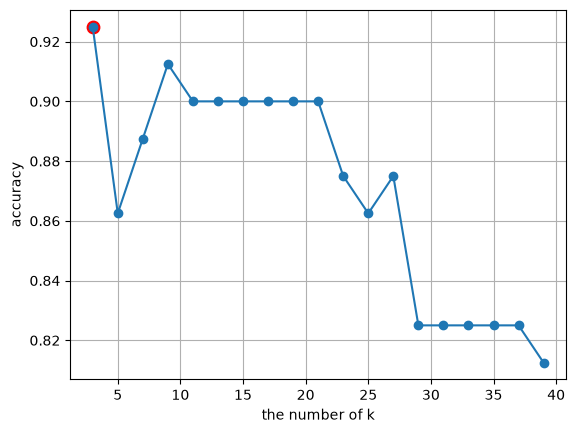

In [ ]:
# k-값 시각화
plt.plot(k_list, cross_validation_score, marker='o')
plt.scatter(result_k, max(cvs), color='red', s=80)
plt.xlabel('the number of k')
plt.ylabel('accuracy')
plt.grid(True)
plt.show()

In [43]:
cvs = cross_validation_score
result_k = k_list[cvs.index(max(cvs))]
str(result_k)

'3'

# - 2개의 특징으로 예측하기 ( 3점슛, 블로킹 )

In [47]:
# 찾아낸 최고의 결과값 k를 가지고 최종 모델 생성
result_knn = KNeighborsClassifier(n_neighbors=result_k)

x_train = df_train[['3P', 'BLK']]
y_train = df_train[['Pos']]

result_knn.fit(x_train, y_train.values.ravel())

KNeighborsClassifier(n_neighbors=3)

In [49]:
# knn 정확도
x_test = df_test[['3P', 'BLK']]
y_test = df_test[['Pos']]

# 테스트 데이터를 넣어서 우리가 생성한 모델로 판단!!
pred = result_knn.predict(x_test)

comparison = pd.DataFrame({'예측값': pred, '정답': y_test.values.ravel()})
comparison




,예측값,정답
0,C,C
1,SG,SG
2,C,SG
3,C,C
4,C,SG
5,C,C
6,SG,SG
7,SG,SG
8,SG,SG
9,C,C


In [54]:
# 정확도 
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test.values.ravel(), pred)

print(f'정확도: {accuracy:.2%}')

정확도: 90.00%


# 3개의 특징으로 예측하기 ( 3점슛, 블로킹, 리바운드 )

In [61]:
result_knn = KNeighborsClassifier(n_neighbors=result_k)

x_train = df_train[['3P', 'BLK', 'TRB']]
y_train = df_train[['Pos']]

result_knn.fit(x_train, y_train.values.ravel())


KNeighborsClassifier(n_neighbors=3)

In [63]:
# knn 정확도 
x_test = df_test[['3P', 'BLK', 'TRB']]
y_test = df_test[['Pos']]

# 테스트 데이터를 넣어서 우리가 생성한 모델로 판단!! 예측요청!!
pred = result_knn.predict(x_test)

# 정답과 예측값 비교값 구하기
accuracy = accuracy_score(y_test.values.ravel(), pred)
print(f'3가지로 특징으로 예측시 정확도: {accuracy:.2%}')


comparison = pd.DataFrame({'예측값': pred, '정답': y_test.values.ravel()})
comparison



3가지로 특징으로 예측시 정확도: 95.00%


,예측값,정답
0,C,C
1,SG,SG
2,C,SG
3,C,C
4,SG,SG
5,C,C
6,SG,SG
7,SG,SG
8,SG,SG
9,C,C


In [ ]:
# 정확도